In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Question 1a

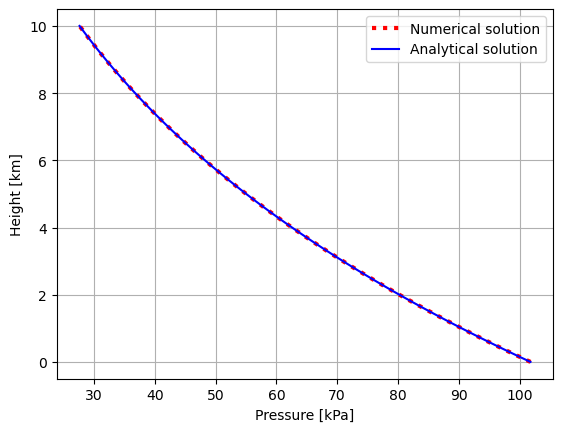

In [3]:
class atmosphere:

    def __init__(self, T_sfc=293, p_sfc=1.018*1e5, gamma=-6):
        self.T_sfc=T_sfc
        self.p_sfc=p_sfc
        self.gamma=gamma

    def p_z(self,z):
        # z must be array

        Rd=287.04
        g=9.81*1e3

        self.z=z
        Tz=self.T_sfc+self.gamma*(np.array(z))

        #numerical
        p=np.zeros(len(z))
        p[0]=self.p_sfc

        for i in range(len(Tz)-1):
            T=(Tz[i]+Tz[i+1])/2
            p[i+1]=p[i]*np.exp(-g*np.gradient(self.z)[0]/(Rd*T))

        #analytical
        self.pz_analytical=self.p_sfc*((self.T_sfc+self.gamma*self.z)/self.T_sfc)**(-g/(Rd*self.gamma))

        
        self.pz=p
        self.density=p/(Rd*Tz)

    def plot_pz(self):
        #in kPa because it's nice
        plt.plot(self.pz/1000,self.z,label='Numerical solution',c='r',linewidth=3,linestyle='dotted')
        plt.plot(self.pz_analytical/1000,self.z,label='Analytical solution',c='b')
        

        plt.xlabel("Pressure [kPa]")
        plt.ylabel("Height [km]")
        plt.grid()
        plt.legend()


model = atmosphere()
model.p_z(np.linspace(0,10,101))

model.plot_pz()

## Question 1b

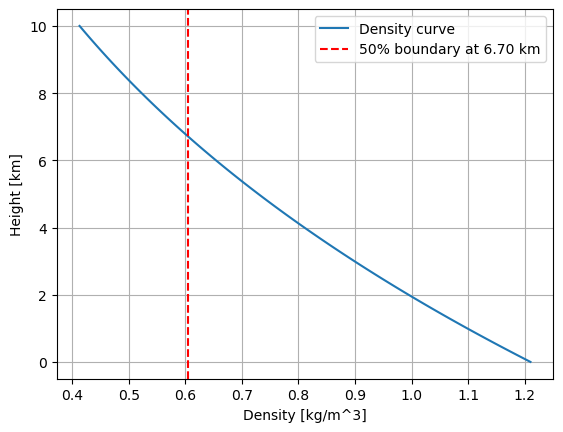

In [4]:
plt.plot(model.density,model.z,label="Density curve")

boundary=0.5*model.density[0]
boundary_height=model.z[np.argmin(abs(boundary-model.density))]

plt.axvline(boundary,c='r',linestyle='--',label=f"50% boundary at {boundary_height:.2f} km")

plt.xlabel("Density [kg/m^3]")
plt.ylabel("Height [km]")
plt.grid()
plt.legend()

## Question 1c

In [5]:
#Slide says q_v = m_v / m_tot
#Doesn't really help much tho...

RH=0.8
T_sfc=np.array([271,303])
z=5

def solve_e_v(T,RH):
    return 610.78*np.exp(17.2694*(T-273.16)/(T-35.86))*RH

e_v = solve_e_v(T_sfc,RH)
p_z = model.pz[model.z==5]

def solve_q_v(e,p):
    Rd = 287.04
    Rv = 8.3144

    return Rd*e/(Rv*p)

q_v = solve_q_v(e_v,p_z)

for i in range(len(q_v)):
    print(f"The water vapor specific humidity at a height of 5 kilometers with a surface temperature of {T_sfc[i]}°K: {q_v[i]:.2f}")

The water vapor specific humidity at a height of 5 kilometers with a surface temperature of 271°K: 0.26
The water vapor specific humidity at a height of 5 kilometers with a surface temperature of 303°K: 2.11


## Question 1d

The maximum value for WVP is 19.305 at 310 °K.
The minumum value for WVP is 0.820 at 260 °K.


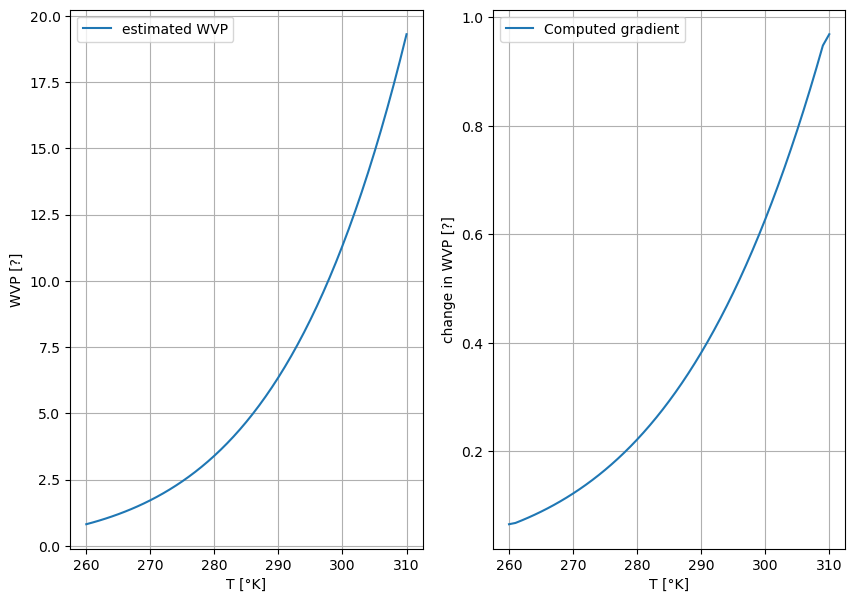

In [6]:
T_range = np.arange(260,310+1,1)
z = 10

def solve_WVP(z,T):
    e = solve_e_v(T,RH)

    Rv = 8.3144

    return e*z / (Rv*T)

WVP = solve_WVP(z,T_range)


plt.figure(figsize=(10,7))

plt.subplot(1,2,1)

plt.plot(T_range,WVP,label="estimated WVP")

plt.xlabel('T [°K]')
plt.ylabel("WVP [?]")
plt.grid()
plt.legend()


plt.subplot(1,2,2)
plt.plot(T_range,np.gradient(WVP),label="Computed gradient")

plt.xlabel('T [°K]')
plt.ylabel("change in WVP [?]")
plt.grid()
plt.legend()


print(f"The maximum value for WVP is {max(WVP):.3f} at {max(T_range)} °K.")
print(f"The minumum value for WVP is {min(WVP):.3f} at {min(T_range)} °K.")

## Question 1e

In [7]:
w = 5 #m/s